# Script for Zonal Wind Stress Perturbations over a circumpolar current-continental shelf slope system
## Includes Figures 3 and 6a.

In [11]:
import numpy as np
import matplotlib.pylab as plt
import xarray as xr
import os
import pickle

#import sys
import xgcm
from xmitgcm import open_mdsdataset
import MITgcmutils
import matplotlib.ticker as mticker

In [2]:
group_scratch_dir = ['/oak/stanford/groups/earlew/nbcoffey', '/oak/stanford/groups/earlew/nbcoffey']

In [3]:
control_home_dir = os.path.join(group_scratch_dir[0], 'research/modeling/MITgcm/experiments')
exp_home_dir = os.path.join(group_scratch_dir[1], 'research/modeling/MITgcm/experiments')

exp_names = ['shelf_H3km_v02_noaabw_branch01_layers_yr250_monthly', 
             'shelf_H3km_v02_noaabw_branch01_incr_wsc_SG_subpolarONLYfixMag_year250_layers',
             'shelf_H3km_v02_noaabw_branch01_25pct_wgb_y1375km_year250_layers',
             'shelf_H3km_v02_noaabw_branch01_contract_fixMag_year250_layers']

exp_names_alias = ['Shelf Only', '$\\tau_E$ N-shift', '$1.25\,\\tau_W^{\\mathrm{Max}}$', '$\\tau_W$ S-shift']

In [4]:
run_config = {}
output = {}
prefix_list = ['THETA_inst', 'VVEL_inst', 'UVEL_inst']#, 'ETAN_inst']
# prefix_list = ['UVEL', 'VVEL', 'WVEL', 'THETA',  'UVELTH', 'VVELTH', 'WVELTH', 
#                     'ETAN', 'UVELSQ', 'VVELSQ', 'WVELSQ', 
#                    'TOTTTEND', 'TFLUX', 'ADVr_TH', 'ADVx_TH', 'ADVy_TH', 
#                    'DFrE_TH', 'DFxE_TH', 'DFyE_TH', 'DFrI_TH', 'oceQsw', 'WTHMASS', 
#                   'LaUH1TH', 'LaVH1TH', 'LaHw1TH','LaHs1TH']#, 'ETAN_inst']
# got an issue with Etan at one of these timesteps. Don't love that.
# Could not find the expected file prefixes ['THETA_inst', 'VVEL_inst', 'UVEL_inst', 'ETAN_inst'] 
# at iternum 4.84303e+06. (Instead found ['UVEL_inst', 'THETA_inst', 'VVEL_inst'])

#iters = [80449, 160898, 241347, 321796, 402245, 482694, 563143, 643592, 724041, 804490, 884939]
iters = 'all'
for i,exp_name in enumerate(exp_names):
    print(i)
    
    results_dir = os.path.join(exp_home_dir, exp_name, 'results')

    # load run_config file (saved at the end of the run_config notebook)
    input_dir = os.path.join(exp_home_dir, exp_name, 'input')
    params_fpath = os.path.join(input_dir, 'params.p')
    with open(params_fpath, 'rb') as f:
        run_config[exp_name] = pickle.load(f)
        
    # load model output as an xarray dataset, which is essentially a netcdf file
    output_ds = open_mdsdataset(data_dir=results_dir, prefix=prefix_list, 
                          geometry='cartesian', iters=iters)
    
    output[exp_name] = output_ds

0
1
2
3


In [5]:
output[exp_name]

<xarray.Dataset>
Dimensions:              (XC: 400, XG: 400, YC: 250, YG: 250, Z: 80, Zl: 80, Zp1: 81, Zu: 80, layer_1TH_bounds: 44, layer_1TH_center: 43, layer_1TH_interface: 42)
Coordinates:
  * XC                   (XC) >f4 5e+03 1.5e+04 2.5e+04 ... 3.985e+06 3.995e+06
  * YC                   (YC) >f4 5e+03 1.5e+04 2.5e+04 ... 2.485e+06 2.495e+06
  * XG                   (XG) >f4 0.0 1e+04 2e+04 ... 3.97e+06 3.98e+06 3.99e+06
  * YG                   (YG) >f4 0.0 1e+04 2e+04 ... 2.47e+06 2.48e+06 2.49e+06
  * Z                    (Z) >f4 -3.42 -10.26 -17.11 ... -2.898e+03 -2.966e+03
  * Zp1                  (Zp1) >f4 0.0 -6.841 -13.69 ... -2.932e+03 -3e+03
  * Zu                   (Zu) >f4 -6.841 -13.69 -20.54 ... -2.932e+03 -3e+03
  * Zl                   (Zl) >f4 0.0 -6.841 -13.69 ... -2.864e+03 -2.932e+03
    rA                   (YC, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dxG                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dyG                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    Depth                (YC, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAz                  (YG, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dxC                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dyC                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAw                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAs                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    drC                  (Zp1) >f4 dask.array<chunksize=(81,), meta=np.ndarray>
    drF                  (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
    PHrefC               (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
    PHrefF               (Zp1) >f4 dask.array<chunksize=(81,), meta=np.ndarray>
    hFacC                (Z, YC, XC) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    hFacW                (Z, YC, XG) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    hFacS                (Z, YG, XC) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskC                (Z, YC, XC) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskW                (Z, YC, XG) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskS                (Z, YG, XC) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    rhoRef               (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
  * layer_1TH_bounds     (layer_1TH_bounds) >f4 -1.0 -0.9 -0.8 ... 11.0 12.0
  * layer_1TH_center     (layer_1TH_center) float32 -0.95 -0.85 ... 10.5 11.5
  * layer_1TH_interface  (layer_1TH_interface) >f4 -0.9 -0.8 -0.7 ... 10.0 11.0
Data variables:
    *empty*

In [ ]:
# load output that has been averaged over the entire run.
# it is set in the model setup - the averaging window is 50 years since Earle set it to be that. You can go back in and change this, but I am not sure how to change your averaging window in an ad hoc manner.

run_config_avgs = {}
avgs = {}

prefix_list = ['UVEL', 'VVEL', 'WVEL', 'THETA',  'VVELTH', 'UVELTH', 
                    'ETAN', 'UVELSQ', 'VVELSQ', 'WVEL']

# prefix_list = ['UVEL', 'VVEL', 'THETA',  'VVELTH', 'UVELTH']

#iters = [80449, 160898, 241347, 321796, 402245, 482694, 563143, 643592, 724041, 804490, 884939]
iters = 'all'
for i,exp_name in enumerate(exp_names):
    print(f"Processing experiment {i}: {exp_name}")
    if i==0:
        results_dir = os.path.join(control_home_dir, exp_name, 'results')
        # load run_config file (saved at the end of the run_config notebook)
        input_dir = os.path.join(control_home_dir, exp_name, 'input')
    else:
        results_dir = os.path.join(exp_home_dir, exp_name, 'results')
        input_dir = os.path.join(exp_home_dir, exp_name, 'input')
    
    params_fpath = os.path.join(input_dir, 'params.p')
    with open(params_fpath, 'rb') as f:
        run_config_avgs[exp_name] = pickle.load(f)
        
    # load model output as an xarray dataset, which is essentially a netcdf file
    avgs_ds = open_mdsdataset(data_dir=results_dir, prefix=prefix_list, 
                          geometry='cartesian', iters=iters)
    avgs[exp_name] = avgs_ds

Processing experiment 0: shelf_H3km_v02_noaabw_branch01_layers_yr250_monthly


In [ ]:
avgs[exp_name]

In [ ]:
# create time array using file names

secsInDays = 3600*24
secsInMons = secsInDays*30
secsInYears = secsInDays*365

# time_yrs_dict = {}

for i,exp_name in enumerate(exp_names):
    
    if i==0:
        results_dir = os.path.join(control_home_dir, exp_name, 'results')
    else:
        results_dir = os.path.join(exp_home_dir, exp_name, 'results')

    
    results_fnames = os.listdir(results_dir)
#     theta_inst_fnames = [fname for fname in results_fnames 
#                          if (fname.startswith('THETA_inst') and fname.endswith('.data'))]


#     # get time stamp info from filenames
#     iters = np.array([int(fname.split('.')[1]) for fname in theta_inst_fnames])
#     iters.sort()
#     #print(iters)

#     mitgcm_params = run_config[exp_name]['mitgcm_params']['data']
#     deltaT = mitgcm_params[2]['deltaT']
#     #print(deltaT)
#     time_secs = iters*deltaT

#     output[exp_name].attrs['time'] = time_secs
    
    # avg ones now
    
    UVELTH_fnames = [fname for fname in results_fnames 
                         if (fname.startswith('UVELTH.') and fname.endswith('.data'))]


    # get time stamp info from filenames
    iters = np.array([int(fname.split('.')[1]) for fname in UVELTH_fnames])
    iters.sort()
    
    mitgcm_params = run_config_avgs[exp_name]['mitgcm_params']['data']
    deltaT = mitgcm_params[2]['deltaT']
    #print(deltaT)
    time_secs_avgs = iters*deltaT

    avgs[exp_name].attrs['time'] = time_secs_avgs

In [ ]:
# print("Snapshot vars:", time_secs.max()/secsInYears)
print("Time-avg vars:", time_secs_avgs.max()/secsInYears)

In [24]:
# make sure you know what the years mean
print(len(time_secs_avgs/secsInYears))
print((time_secs_avgs/secsInYears))
print((time_secs_avgs))
avgs[exp_names[0]]['time']

361
[250.00000127 250.08334602 250.16665969 250.25000444 250.33331811
 250.41666286 250.50000761 250.58332128 250.66666603 250.75001078
 250.83332445 250.9166692  251.00001395 251.08332763 251.16667237
 251.24998605 251.3333308  251.41667555 251.49998922 251.58333397
 251.66667872 251.74999239 251.83333714 251.91668189 251.99999556
 252.08334031 252.16665398 252.24999873 252.33334348 252.41665715
 252.5000019  252.58334665 252.66666032 252.75000507 252.83331875
 252.9166635  253.00000824 253.08332192 253.16666667 253.25001142
 253.33332509 253.41666984 253.50001459 253.58332826 253.66667301
 253.74998668 253.83333143 253.91667618 253.99998985 254.0833346
 254.16667935 254.24999302 254.33333777 254.41665145 254.49999619
 254.58334094 254.66665462 254.74999937 254.83334411 254.91665779
 255.00000254 255.08334729 255.16666096 255.25000571 255.33331938
 255.41666413 255.50000888 255.58332255 255.6666673  255.75001205
 255.83332572 255.91667047 256.00001522 256.08332889 256.16667364
 256.24

<xarray.DataArray 'time' (time: 361)>
array([8044898000000000, 8047580000000000, 8050261000000000, ...,
       9004922000000000, 9007604000000000, 9010286000000000],
      dtype='timedelta64[ns]')
Coordinates:
    iter     (time) int64 dask.array<chunksize=(1,), meta=np.ndarray>
  * time     (time) timedelta64[ns] 93 days 02:41:38 ... 104 days 06:51:26
Attributes:
    standard_name:  time
    long_name:      Time
    axis:           T
    calendar:       gregorian

In [12]:
import numpy as np

def monthly_to_yearly_inmemory(
    ds,
    time_dim="time",
    months_per_year=12,
    first_record_is_annual=True,
):
    """
    Convert monthly dataset to yearly means in memory.
    
    If first_record_is_annual=True:
      - ds[0] is already annual mean (keep as-is)
      - ds[1:] are monthly means -> average into 12-month blocks
    
    Returns dataset with clean integer time index [0, 1, 2, ...]
    """
    
    if first_record_is_annual:
        # Keep first record
        first_annual = ds.isel({time_dim: 0})
        first_annual = first_annual.expand_dims({time_dim: [0]})
        
        # Process remaining monthly records
        rest_monthly = ds.isel({time_dim: slice(1, None)})
        nT = rest_monthly.sizes[time_dim]
        nY = nT // months_per_year
        
        yearly_list = [first_annual]
        
        for iyear in range(nY):
            start_idx = iyear * months_per_year
            end_idx = start_idx + months_per_year
            year_mean = rest_monthly.isel({time_dim: slice(start_idx, end_idx)}).mean(dim=time_dim)
            year_mean = year_mean.expand_dims({time_dim: [iyear + 1]})
            yearly_list.append(year_mean)
        
        ds_yearly = xr.concat(yearly_list, dim=time_dim)
        
    else:
        # All records are monthly
        nT = ds.sizes[time_dim]
        nY = nT // months_per_year
        ds_trimmed = ds.isel({time_dim: slice(0, nY * months_per_year)})
        
        yearly_list = []
        for iyear in range(nY):
            start_idx = iyear * months_per_year
            end_idx = start_idx + months_per_year
            year_mean = ds_trimmed.isel({time_dim: slice(start_idx, end_idx)}).mean(dim=time_dim)
            year_mean = year_mean.expand_dims({time_dim: [iyear]})
            yearly_list.append(year_mean)
        
        ds_yearly = xr.concat(yearly_list, dim=time_dim)
    
    # Replace time coordinate with simple integers
    ds_yearly['time'] = np.arange(len(ds_yearly.time))
    
    return ds_yearly


# --------------------------------------------------------------------
# Convert all experiments to yearly means IN MEMORY
# --------------------------------------------------------------------
print("Converting monthly data to yearly means...")

yearly_avgs = {}
for exp_name in exp_names:
    print(f"  Processing {exp_name}...")
    yearly_avgs[exp_name] = monthly_to_yearly_inmemory(
        avgs[exp_name],
        time_dim="time",
        months_per_year=12,
        first_record_is_annual=True
    )
    print(f"    -> {len(yearly_avgs[exp_name].time)} years")

print("\nYearly averaging complete! Now using yearly_avgs dictionary.\n")

Converting monthly data to yearly means...
  Processing shelf_H3km_v02_noaabw_branch01_layers_yr250_monthly...
    -> 31 years
  Processing shelf_H3km_v02_noaabw_branch01_incr_wsc_SG_subpolarONLYfixMag_year250_layers...
    -> 31 years
  Processing shelf_H3km_v02_noaabw_branch01_25pct_wgb_y1375km_year250_layers...
    -> 31 years
  Processing shelf_H3km_v02_noaabw_branch01_contract_fixMag_year250_layers...
    -> 31 years

Yearly averaging complete! Now using yearly_avgs dictionary.



# Figure 6 a)

In [11]:
import os

# Create output directory
output_dir = 'all_mht_years_v1'
os.makedirs(output_dir, exist_ok=True)

fz       = 20
tick_sz  = 18

tidxequil = 0
year_range = [0, 10]  # Just year 0 and year 10

Lx = 4000*1e3 # meters
rho = 1025 # kg/m3
c_w = 4100 # J/C/kg

colors = {
    'vT': 'k',
    'vT_xtmean': 'b',
    'vT_tmean': 'g',
    'vT_eddy': 'r'
}

linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 2, 1, 2))]

# Loop through each year
for year_offset in year_range:
    print(f"\n{'='*60}")
    print(f"Processing year_offset = {year_offset}")
    print(f"{'='*60}")
    
    tidx = tidxequil + year_offset
    
    fig, ax = plt.subplots(figsize=(8, 6.9), constrained_layout=True)
    
    for i, exp_name in enumerate(exp_names):
        print(f"  Experiment [{i+1}/{len(exp_names)}]: {exp_name}")
        
        # Use the yearly-averaged dataset
        print(f"    - Creating grid...")
        grid = xgcm.Grid(yearly_avgs[exp_name], periodic=['X'])
        ds = yearly_avgs[exp_name]
        
        print(f"    - Computing theta_min...")
        theta_avg = ds['THETA']
        theta_min = theta_avg.min()

        print(f"    - Computing transports...")
        v_transport = ds.VVEL * ds.dxG * ds.hFacS * ds.drF
        vT_transport = ds.VVELTH * ds.dxG * ds.hFacS * ds.drF

        print(f"    - Interpolating to Y points...")
        v_transport_intp = grid.interp(v_transport,'Y', boundary='extend')
        vT_intp = grid.interp(vT_transport, 'Y', boundary='extend')

        print(f"    - Computing zonal/vertical integrals...")
        vT_mean_xzint = ((ds.THETA-theta_min)*v_transport_intp).sum(dim=['Z', 'XC'])
        vT_total_xzint = (vT_intp-v_transport_intp*theta_min).sum(dim=['Z', 'XC'])
        vT_prime_xzint  = vT_total_xzint - vT_mean_xzint

        vT_bracketmean_xzint = ((ds.THETA.mean(dim='XC') - theta_min) * v_transport_intp.sum(dim='XC')).sum(dim=['Z'])
        vT_starmean_xzint = vT_mean_xzint - vT_bracketmean_xzint

        print(f"    - Computing MHT components...")
        mht_mean = rho*c_w*vT_mean_xzint*1e-15
        mht_total = rho*c_w*vT_total_xzint*1e-15
        mht_eddy = rho*c_w*vT_prime_xzint*1e-15
        mht_bracketmean = rho*c_w*vT_bracketmean_xzint*1e-15
        mht_starmean = rho*c_w*vT_starmean_xzint*1e-15

        print(f"    - Time-averaging from year {tidxequil} to {tidx} and computing...")
        mht_total_avg = mht_total[tidxequil:tidx+1].mean(dim='time').compute()
        mht_bracketmean_avg = mht_bracketmean[tidxequil:tidx+1].mean(dim='time').compute()
        mht_starmean_avg = mht_starmean[tidxequil:tidx+1].mean(dim='time').compute()
        mht_eddy_avg = mht_eddy[tidxequil:tidx+1].mean(dim='time').compute()

        linestyle = linestyles[i % len(linestyles)]
        label_base = exp_names_alias[i]

        print(f"    - Plotting...")
        # Plot the pre-computed averages
        plt.plot(mht_total_avg, ds.YC/1e3, color=colors['vT'], label=f'{label_base}  Total', lw=2, linestyle=linestyle)
        plt.plot(mht_bracketmean_avg, ds.YC/1e3, color=colors['vT_xtmean'], label=f'{label_base}  Eulerian MOC', lw=2, linestyle=linestyle)
        plt.plot(mht_starmean_avg, ds.YC/1e3, color=colors['vT_tmean'], label=f'{label_base}  Gyres & Standing Eddies', lw=2, linestyle=linestyle)
        plt.plot(mht_eddy_avg, ds.YC/1e3, color=colors['vT_eddy'], label=f'{label_base}  Transient Eddies', lw=2, linestyle=linestyle)
        
        print(f"    ✓ Done with {exp_name}")

    print(f"  Setting up axes and legends...")
    ax.set_ylabel('Meridional Distance  $y$  (km)', fontsize=fz)
    ax.set_xlabel('Meridional Heat Transport  (PW)', fontsize=fz)
    ax.set_xlim(-0.15, 0.15)
    ax.set_ylim(0, 2500)
    ax.grid(True, alpha=0.3)
    ax.axvline(0, ls='-.', c='0.5')
    ax.tick_params(axis='both', which='major', labelsize=tick_sz)

    from matplotlib.lines import Line2D
    exp_handles = [Line2D([], [], color='k', lw=2, ls=linestyles[i % len(linestyles)], label=alias) 
                   for i, alias in enumerate(exp_names_alias)]
    leg_exp = ax.legend(handles=exp_handles, loc='lower right', fontsize=fz-2, frameon=False, handlelength=1.5)
    ax.add_artist(leg_exp)

    term_handles = [
        Line2D([], [], color=colors['vT'],        lw=2, label='Total'),
        Line2D([], [], color=colors['vT_xtmean'], lw=2, label='Eulerian MOC'),
        Line2D([], [], color=colors['vT_tmean'],  lw=2, label='Gyres & Meanders'),
        Line2D([], [], color=colors['vT_eddy'],   lw=2, label='Transient Eddies')
    ]
    leg_term = ax.legend(handles=term_handles, loc='lower left', fontsize=fz-2, frameon=False, handlelength=1.5)

    fig.suptitle(f'Meridional Heat Transport (Years {tidxequil} to {tidx})', fontsize=fz+2)

    filename = f'mht_profile_all_year_{year_offset:02d}.pdf'
    filepath = os.path.join(output_dir, filename)
    
    print(f"  Saving figure: {filename}")
    fig.savefig(filepath, dpi=300, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    print(f"  ✓ Saved: {filepath}")

print(f"\n{'='*60}")
print(f'All figures saved to {output_dir}/')
print(f"{'='*60}")


Processing year_offset = 0
  Experiment [1/4]: shelf_H3km_v02_noaabw_branch01_layers_yr250_monthly
    - Creating grid...
    - Computing theta_min...
    - Computing transports...
    - Interpolating to Y points...
    - Computing zonal/vertical integrals...
    - Computing MHT components...
    - Time-averaging from year 0 to 0 and computing...
    - Plotting...
    ✓ Done with shelf_H3km_v02_noaabw_branch01_layers_yr250_monthly
  Experiment [2/4]: shelf_H3km_v02_noaabw_branch01_incr_wsc_SG_subpolarONLYfixMag_year250_layers
    - Creating grid...
    - Computing theta_min...
    - Computing transports...
    - Interpolating to Y points...
    - Computing zonal/vertical integrals...
    - Computing MHT components...
    - Time-averaging from year 0 to 0 and computing...
    - Plotting...
    ✓ Done with shelf_H3km_v02_noaabw_branch01_incr_wsc_SG_subpolarONLYfixMag_year250_layers
  Experiment [3/4]: shelf_H3km_v02_noaabw_branch01_25pct_wgb_y1375km_year250_layers
    - Creating grid...

# Figure 3 c), e), g)

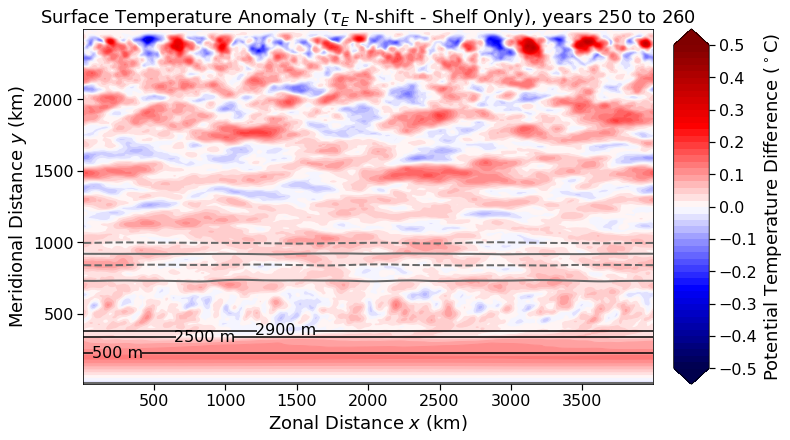

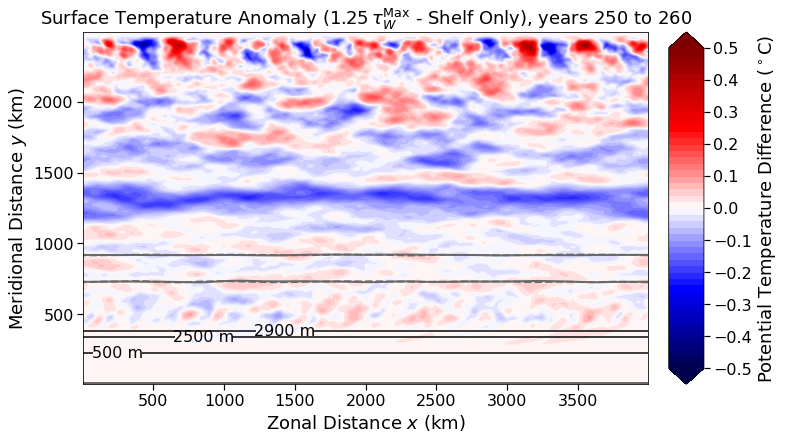

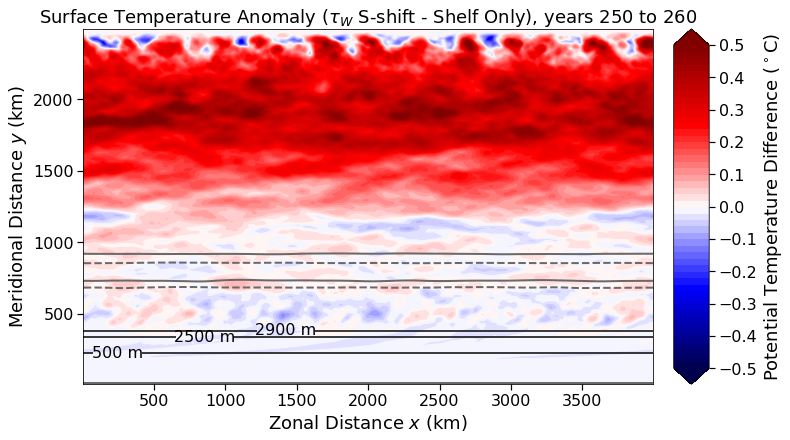

In [13]:
import matplotlib.ticker as mticker
fz=18

tavgvars = True
TIME_RESOLUTION = 'monthly'  # or 'yearly'
time_multiplier = 12 if TIME_RESOLUTION == 'monthly' else 1

vble = 'THETA'
if tavgvars:
    tidxequil = 1#-29 * time_multiplier  # Excludes year 249-250
    tidx = tidxequil + 10 * time_multiplier
else:
    tidx = -1
zidx = 0

# Updated color levels for temperature difference
clvls = np.arange(-0.5, 0.51, 0.02)
dep_lvls = [500, 2500, 2900]

# Store control experiment data
control_data = {}

for i, exp_name in enumerate(exp_names):
    # Process variable data
    if tavgvars:
        ds = avgs[exp_name]
        vble_map = ds[vble][tidxequil:tidx, 0, :, :]  # 0 index for surface layer
        vble_map = vble_map.mean(dim='time')
        vble_map.attrs = ds[vble].attrs
    else:
        ds = output[exp_name]
        vble_map = ds[vble][tidx, zidx, :, :]
    
    x = ds['XC']/1e3
    y = ds['YC']/1e3
    z = ds['Z'].values
    
    # Calculate streamfunction for all experiments
    grid = xgcm.Grid(ds, periodic=['X'])
    u_bt = (ds.UVEL * ds.hFacW * ds.drF).sum(dim='Z')
    v_bt = (ds.VVEL * ds.hFacS * ds.drF).sum(dim='Z')
    psi = grid.cumsum(-u_bt * ds.dyG, 'Y', boundary='fill')
    psi_mean = psi[tidxequil:tidx, :, :].mean('time')/1e6
    
    if i == 0:
        # Store control experiment data
        control_data = {
            'vble_map': vble_map,
            'psi': psi_mean,
            'x': x,
            'y': y,
            'z': z,
            'ds': ds
        }
        continue  # Skip plotting for control experiment
    
    # For perturbation experiments, create difference plot
    fig, axes = plt.subplots(figsize=(12, 6), constrained_layout=True)
    
    # Calculate differences
    vble_diff = vble_map - control_data['vble_map']
    
    cmap = 'seismic'
    
    # Plot the difference
    im = plt.contourf(x, y, vble_diff, clvls, vmin=clvls.min(), vmax=clvls.max(), 
                     cmap=cmap, extend='both', antialiased=True)
    for col in im.collections:
        col.set_edgecolor('face')
        col.set_rasterized(True)
    
#     # Add bathymetry contours
#     CS = plt.contour(x, y, ds.Depth, dep_lvls, colors='k')
#     plt.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')
    # Add bathymetry contours (excluding the northern boundary)
    depth_for_contour = np.copy(ds.Depth)
    depth_for_contour[-1, :] = np.nan

    CS = plt.contour(x, y, depth_for_contour, dep_lvls, colors='k')
    plt.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')
    
    # Add streamfunction contours
    psi_lvl = 50
    CS0 = plt.contour(control_data['x'], control_data['y'], control_data['psi'], 
                     levels=[-50, 0, psi_lvl], colors='dimgray', linestyles='-', linewidths=2)
    CS1 = plt.contour(x, y, psi_mean, levels=[-50, 0, psi_lvl], 
                     colors='dimgray', linestyles='--', linewidths=2)
#     plt.clabel(CS0, inline=True, fontsize=fz-2, fmt='%d Sv')
    # Label only the solid/control contours, then move those labels northward.
    # x and y are in km, so 50 means a 50-km displacement.
#     label_dy = 50

#     labels0 = axes.clabel(CS0, inline=False, fontsize=fz-2, fmt='%d Sv')

#     for label in labels0:
#         x_label, y_label = label.get_position()
#         label.set_position((x_label, y_label + label_dy))

    plt.ylabel("Meridional Distance $y$ (km)", fontsize=fz)
    plt.xlabel("Zonal Distance $x$ (km)", fontsize=fz)
    
    tstmp1 = ds.attrs['time'][tidxequil]/secsInYears
    tstmp2 = ds.attrs['time'][tidx]/secsInYears
    plt.title(f"Surface Temperature Anomaly ({exp_names_alias[i]} - {exp_names_alias[0]}), years $%.0f$ to $%.0f$" %(tstmp1, tstmp2), fontsize=fz)
    
    cb = plt.colorbar(im, ticks=np.arange(-0.5, 0.51, 0.1))
    cb.set_label('Potential Temperature Difference ($^\circ$C)', fontsize=fz)
    
    axes.set_aspect('equal', adjustable='box')
    axes.xaxis.set_major_formatter(mticker.FormatStrFormatter('%d'))
    axes.yaxis.set_major_formatter(mticker.FormatStrFormatter('%d'))
    axes.tick_params(axis='both', which='major', labelsize=fz-2, length=6, width=1.2)
    cb.ax.tick_params(axis='y', which='major', labelsize=fz-2, length=6, width=1.2)

    # Save with experiment-specific filename
    fig.savefig(f'v1_nolabel_noNbound_{exp_name}_difference_THETA_baropsi_surface.pdf',
                dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
    
    plt.show()

# Figure 3 d), f), h)

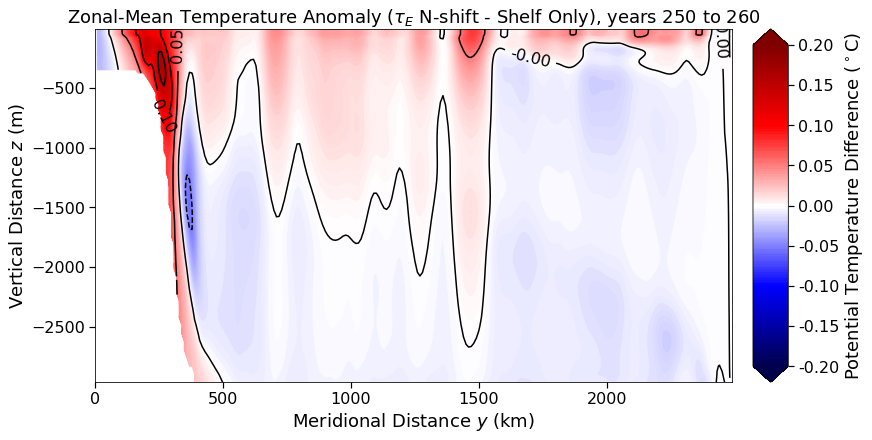

Max absolute difference for shelf_H3km_v02_noaabw_branch01_incr_wsc_SG_subpolarONLYfixMag_year250_layers: 0.1630725860595703


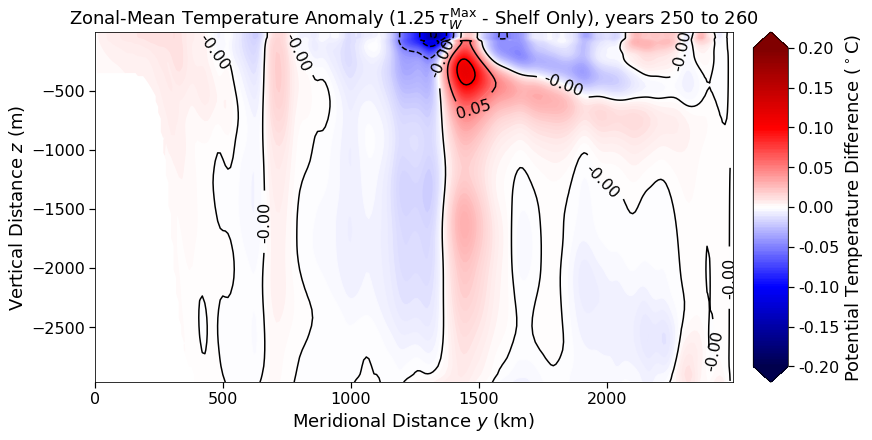

Max absolute difference for shelf_H3km_v02_noaabw_branch01_25pct_wgb_y1375km_year250_layers: 0.15315675735473633


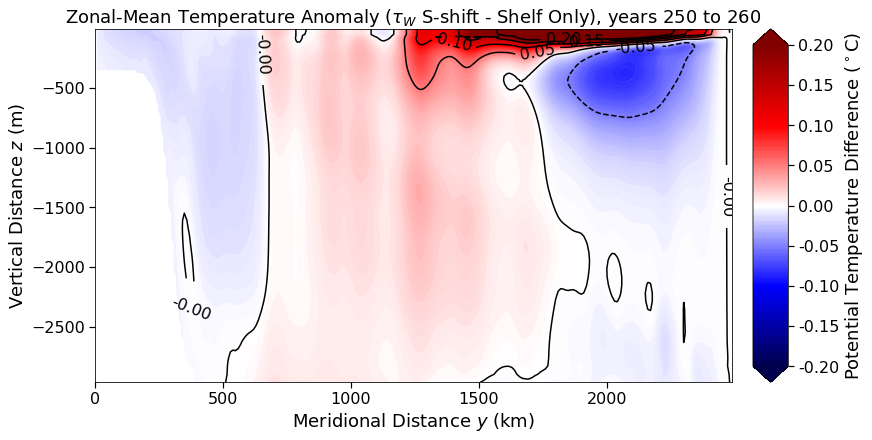

Max absolute difference for shelf_H3km_v02_noaabw_branch01_contract_fixMag_year250_layers: 0.3925786018371582


In [48]:
import matplotlib.ticker as mticker

fz = 18  # Font size
vble = 'THETA'
xs1 = 0#1000e3
xs2 = -1#2500e3

# Store control experiment data
control_data = {}

for i, exp_name in enumerate(exp_names):
    ds = yearly_avgs[exp_name]
    
    # Set time indices
    tidxequil = 1  # Start at year 1 (skipping the initial annual mean at index 0)
    tidx = tidxequil + 9  # = 10, so years 1-9 (10 years total)
    
    # Get the data for this experiment and actual coordinate values
    xs1_coord = ds['XC'].isel(XC=xs1).values if xs1 == 0 else xs1
    xs2_coord = ds['XC'].isel(XC=xs2).values if xs2 == -1 else xs2
    vble_sect = ds[vble][tidxequil:tidx, :, :, :].sel(XC=slice(xs1_coord, xs2_coord)).mean(dim='XC').mean(dim='time')
    vble_sect = vble_sect.where(vble_sect!=0)
    units = ds[vble].units
    
    if i == 0:
        # Store control experiment data
        # Calculate years based on indices (year 0 = 249-250, year 1 = first full year after, etc.)
        year_start = 250 + tidxequil  # tidxequil=1 -> year 251
        year_end = 250 + tidx  # tidx=10 -> year 260
        
        control_data = {
            'vble_sect': vble_sect,
            'y': ds['YG']/1e3,
            'z': ds['Z'].values,
            'tstmp1': year_start,
            'tstmp2': year_end,
            'units': units
        }
        continue  # Skip plotting for control experiment
    
    # For perturbation experiments, create difference plot
    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)  # Same size as above
    
    # Interpolate perturbation data to control grid and calculate difference
    vble_sect_interp = vble_sect.interp(Z=control_data['z'])
    vble_sect_diff = vble_sect_interp - control_data['vble_sect']
    
    y = control_data['y']
    z = control_data['z']
    
    # Plotting the difference with high-quality styling
    clvls = np.linspace(-0.20, 0.20, 201)  # 201 levels for very smooth gradient
    cmap = 'seismic'
    
    im = plt.contourf(y, z, vble_sect_diff, clvls, vmin=-0.2, vmax=0.2, 
                     cmap=cmap, extend='both', antialiased=True)
    # Make edges smooth
    for col in im.collections:
        col.set_edgecolor('face')
        col.set_rasterized(True)
    
    # Use fewer contour lines for the black contours to avoid overcrowding
    contour_lvls = np.arange(-0.20, 0.201, 0.05)  # Contour every 0.05
    cs = plt.contour(y, z, vble_sect_diff, contour_lvls, colors='k')
    plt.clabel(cs, cs.levels, inline=True, fontsize=fz-2, fmt='%.2f')
    
    # Add labels with proper formatting (CHANGED)
    plt.ylabel("Vertical Distance $z$ (m)", fontsize=fz)
    plt.xlabel("Meridional Distance $y$ (km)", fontsize=fz)
    
    # Updated title with experiment alias and proper formatting
    plt.title("Zonal-Mean Temperature Anomaly (%s - %s), years %.0f to %.0f" %
              (exp_names_alias[i], exp_names_alias[0], 
               control_data['tstmp1']-1, control_data['tstmp2']), fontsize=fz)
    
    # Define specific tick values for the colorbar
    tick_values = np.array([-0.2, -0.15, -0.1, -0.05, 0, 0.05, 0.1, 0.15, 0.2])
    
    # Add colorbar with custom ticks (CHANGED)
    cbar = fig.colorbar(im, ax=ax, orientation='vertical', ticks=tick_values)
    cbar.set_label('Potential Temperature Difference ($^\circ$C)', fontsize=fz)
    
    # Apply formatting to axes and ticks
    int_fmt = mticker.FormatStrFormatter('%.0f')
    
    ax.tick_params(axis='both', which='major',
                   labelsize=fz-2,
                   length=6, width=1.2)
    
    # Format colorbar ticks
    cbar.ax.tick_params(axis='y', which='major',
                        labelsize=fz-2,
                        length=6, width=1.2)
    
    # Optional: format the colorbar tick labels with the desired precision
    cbar.ax.set_yticklabels([f'{val:.2f}' for val in tick_values])
    
    # Save with experiment-specific filename
    fig.savefig(f'THETA_difference_{exp_names_alias[i]}_section_{xs1}_{xs2}_yr250.pdf',
                dpi=300,
                bbox_inches='tight',
                facecolor='white',
                transparent=False)
    
    plt.show()
    print(f"Max absolute difference for {exp_name}: {np.nanmax(np.abs(vble_sect_diff.values))}")

# Figure 3 a)

/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:69: UserWarning: linewidths is ignored by contourf


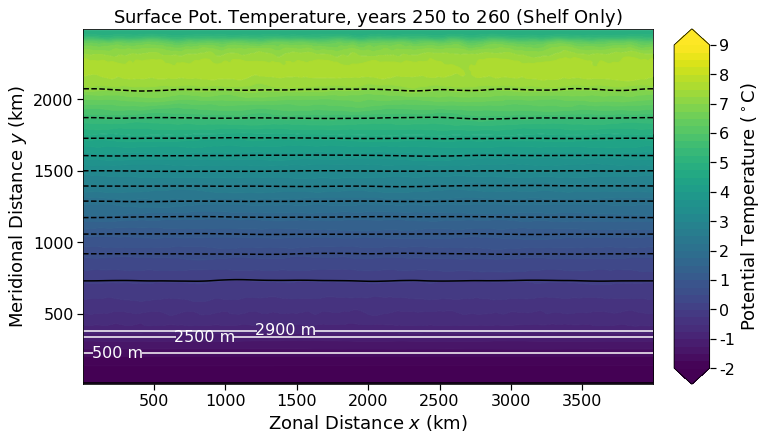

In [14]:
# 10 years, 30 Sv

import matplotlib.ticker as mticker

# put those barotropic streamlines on top of potential temperature
fz=18

tavgvars = True

vble = 'THETA'
if tavgvars:
#     tidxequil = -10 # end of sim plot, use -2
    tidxequil = 1  # Start at year 1 (skip the initial year 249-250 at index 0)
    tidx = tidxequil+9
else:
    tidx = -1
zidx = 0

clvls = np.arange(-2.0, 9.1, 0.25)
dep_lvls = [500, 2500, 2900]

# Loop through all experiments
for i, exp_name in enumerate(exp_names):
    if i>0:
        break
    # Create a new figure for each experiment
    fig, axes = plt.subplots(figsize=(12, 6), constrained_layout=True)
    
    if tavgvars:
        ds = yearly_avgs[exp_name]
        # Select only the surface layer (topmost Z level)
        vble_map = ds[vble][tidxequil:tidx, 0, :, :]  # 0 index for surface layer
        # Average over time
        vble_map = vble_map.mean(dim='time')
        vble_map.attrs = ds[vble].attrs
    else:
        ds = output[exp_name]
        vble_map = ds[vble][tidx, zidx, :, :]
    
    x = ds['XC']/1e3
    y = ds['YC']/1e3
    z = ds['Z'].values
    
    # Calculate streamfunction
    grid = xgcm.Grid(ds, periodic=['X'])
    u_bt = (ds.UVEL * ds.hFacW * ds.drF).sum(dim='Z')
    v_bt = (ds.VVEL * ds.hFacS * ds.drF).sum(dim='Z')
    psi = grid.cumsum(-u_bt * ds.dyG, 'Y', boundary='fill')
    psi_mean = psi[tidxequil:tidx, :, :].mean('time')/1e6
    
#     # Automatically determine streamfunction contour spacing
#     psi_max = np.abs(psi_mean).max()
#     if psi_max > 150:
#         psi_spacing = 50
#     else:
#         psi_spacing = 10
    
#     # Create appropriate range based on the maximum value and spacing
#     psi_range = int(np.ceil(psi_max / psi_spacing) * psi_spacing)
#     psi_lvls = np.arange(-psi_range, psi_range + 1, psi_spacing)
    psi_lvls = [-550, -500, -450, -400, -350, -300, -250, -200, -150, -100, -50, 0, 30]
    
    vble_map = vble_map.where(vble_map!=0)
    units = vble_map.units
    cmap = 'viridis'

    # Create contour plot
    im = plt.contourf(x, y, vble_map, clvls, vmin=clvls.min(), vmax=clvls.max(), 
                     cmap=cmap, extend='both', antialiased=True, linewidths=0)
    for col in im.collections:
        col.set_edgecolor('face')
        col.set_rasterized(True)
    
#     # Add bathymetry contours
#     CS = plt.contour(x, y, ds.Depth, dep_lvls, colors='w')
#     plt.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')
    # Add bathymetry contours (excluding the northern boundary)
    depth_for_contour = np.copy(ds.Depth)
    depth_for_contour[-1, :] = np.nan

    CS = plt.contour(x, y, depth_for_contour, dep_lvls, colors='w')
    plt.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')
    
    # Add streamfunction contours with adaptive spacing
    CS2 = plt.contour(x, y, psi_mean, psi_lvls, colors='k')
#     plt.clabel(CS2, inline=True, fontsize=fz-2, fmt='%d Sv')

    plt.ylabel("Meridional Distance $y$ (km)", fontsize=fz)
    plt.xlabel("Zonal Distance $x$ (km)", fontsize=fz)

    if tavgvars:
        # Calculate years based on indices (year 0 = 249-250, year 1 = first full year after, etc.)
        year_start = 250 + tidxequil  # tidxequil=1 -> year 251
        year_end = 250 + tidx  # tidx=10 -> year 260
        # Use exp_names_alias[i] in the title
        plt.title("Surface Pot. Temperature, years $%.0f$ to $%.0f$ (%s)" %(year_start-1, year_end, exp_names_alias[i]), fontsize=fz)
    else:
        tstmp = ds.attrs['time'][tidx]/secsInYears
        plt.title("%s at $z=%.2f$ m, snapshot $t=%.2f$ years (%s)" %(vble, z[zidx], tstmp, exp_names_alias[i]), fontsize=fz)
    
    cb = plt.colorbar(im)
    cb.set_label('Potential Temperature ($^\circ$C)', fontsize=fz)

    axes.set_aspect('equal', adjustable='box')

    # Format axes
    int_fmt = mticker.FormatStrFormatter('%.0f')
    axes.xaxis.set_major_formatter(int_fmt)
    axes.yaxis.set_major_formatter(int_fmt)
    axes.tick_params(axis='both', which='major', labelsize=fz-2, length=6, width=1.2)

    # Format colorbar
    cb.set_ticks(range(-2, 10))  # For every integer from -2 to 9
    cb.ax.yaxis.set_major_formatter(int_fmt)
    cb.ax.tick_params(axis='y', which='major', labelsize=fz-2, length=6, width=1.2)

    # Save with experiment-specific filename
    fig.savefig(f'v1_nolabel_noNbound_{exp_names_alias[i]}_THETA_shelfonly_bathy_baropsi_surf_over{-1*tidxequil}years.pdf',
                dpi=300, bbox_inches='tight', facecolor='white', transparent=False)

    plt.show()

# Figure 3 b)

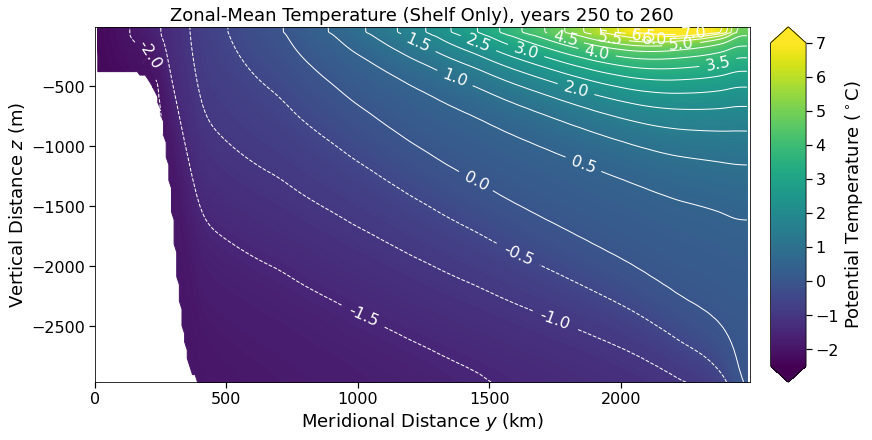

In [38]:
import matplotlib.ticker as mticker

fz = 18  # Font size
vble = 'THETA'
tidxequil = 1  # Start at year 1 (skip initial year 249-250 at index 0)
tidx = tidxequil + 9  # = 10, so years 1-9 (10 years total)
xs1 = 0  # 1000e3
xs2 = -1  # 2500e3

# Loop through all experiments to create control plots
for i, exp_name in enumerate(exp_names):
    if i > 0:  # Only process first experiment
        break
    
    # Create a new figure for each experiment
    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)  # Same size as anomaly code
    
    # Process data for current experiment
    ds = yearly_avgs[exp_name]  # CHANGED: Use yearly data
    
    # Get the data for this experiment and actual coordinate values
    xs1_coord = ds['XC'].isel(XC=xs1).values if xs1 == 0 else xs1
    xs2_coord = ds['XC'].isel(XC=xs2).values if xs2 == -1 else xs2
    vble_sect = ds[vble][tidxequil:tidx, :, :, :].sel(XC=slice(xs1_coord, xs2_coord)).mean(dim='XC').mean(dim='time')
    vble_sect = vble_sect.where(vble_sect != 0)
    
    units = ds[vble].units
    y = ds['YG']/1e3
    z = ds['Z'].values
    year_start = 250 + tidxequil-1  # tidxequil=1 -> year 251
    year_end = 250 + tidx
    
    # Plot the experiment with high-quality styling (matching anomaly code)
    clvls = np.arange(-2.5, 7.01, 0.05)  # Fine levels for smooth gradient
    cmap = 'viridis'
    
    im = plt.contourf(y, z, vble_sect, clvls,
                     vmin=clvls.min(), vmax=clvls.max(),
                     cmap=cmap, extend='both', antialiased=True)
    
    # Make edges smooth (matching anomaly code)
    for col in im.collections:
        col.set_edgecolor('face')
        col.set_rasterized(True)
    
    # Add temperature contours every 0.5°C
    temp_contours = np.arange(-2.0, 7.5, 0.5)  # Every 0.5°C
    cs = plt.contour(y, z, vble_sect, temp_contours, colors='w', linewidths=1)
    
    # Format contour labels to 1 decimal place
    fmt = lambda x: f'{x:.1f}'
    plt.clabel(cs, cs.levels, inline=True, fontsize=fz-2, fmt=fmt)
    
    # Add labels with proper formatting (SAME AS ANOMALY CODE)
    plt.ylabel("Vertical Distance $z$ (m)", fontsize=fz)
    plt.xlabel("Meridional Distance $y$ (km)", fontsize=fz)
    
    # Title with experiment alias and proper formatting (matching anomaly style)
    plt.title("Zonal-Mean Temperature (%s), years %.0f to %.0f" %
              (exp_names_alias[i], year_start, year_end), fontsize=fz)
    
    # Add colorbar (SAME FORMATTING AS ANOMALY CODE)
    cbar = fig.colorbar(im, ax=ax, orientation='vertical')
    cbar.set_label('Potential Temperature ($^\circ$C)', fontsize=fz)
    
    # Apply formatting to axes and ticks (SAME AS ANOMALY CODE)
    int_fmt = mticker.FormatStrFormatter('%.0f')
    
    ax.tick_params(axis='both', which='major',
                   labelsize=fz-2,
                   length=6, width=1.2)
    
    # Format colorbar ticks (SAME AS ANOMALY CODE)
    cbar.ax.tick_params(axis='y', which='major',
                        labelsize=fz-2,
                        length=6, width=1.2)
    
    # Save the figure with experiment-specific filename (matching pattern)
    fig.savefig(f'THETA_control_{exp_names_alias[i]}_section_{xs1}_{xs2}_yr1to10.pdf',  # CHANGED: filename to reflect years 1-10
                dpi=300,
                bbox_inches='tight',
                facecolor='white',
                transparent=False)
    
    plt.show()